In [1]:
import glob
import gc
import random

import numpy as np
import pandas as pd

from scipy.stats import median_abs_deviation, percentileofscore

import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc

import pegasus as pg
from pegasusio import UnimodalData, MultimodalData

%matplotlib inline

sc.settings.n_jobs = 25

random.seed(0)
np.random.seed(0)
sc.settings.seed = 0

In [2]:
## From Cellbender Import ##

rao_adata = sc.read_h5ad('/mnt/sdb/scz_meta_analysis_processed/studies/rao_gogos/anndata_objs/rao_cellbendered.h5ad')

rao_adata.obs['Run'] = [i.split('_')[0] for i in rao_adata.obs_names]

rao_adata.obs['barcodes'] = rao_adata.obs_names

# filter ambient rna
rao_adata = rao_adata[rao_adata.obs['cell']].copy()

In [3]:
## Cells After Ambient RNA Removal ##

rao_adata.shape[0]

144551

In [4]:
## Merge SRA Metadata ##

rao_sra_metadata = pd.read_csv('/mnt/sda/scz_meta_analysis/rao_gogos_nature_comm_2025/metadata/Rao_SRA_RunTable.csv')

rao_sra_metadata_essential = rao_sra_metadata[['Run', 'BioProject', 'BioSample',
                                               'cell_line', 'Center Name', 'Experiment', 'genotype',
                                               'Instrument', 'Library Name', 'ReleaseDate', 'create_date', 
                                               'Sample Name', 'treatment']]

rao_adata.obs = rao_adata.obs.merge(rao_sra_metadata_essential, left_on='Run', right_on='Run', how='left')

rao_adata.obs.index = rao_adata.obs['barcodes']

rao_adata.obs.rename({'cell_line': 'Cell_Line'}, inplace=True, axis=1)

rao_adata.obs['Donor'] = rao_adata.obs['Cell_Line'] # cell lines are all unique donors

In [5]:
## Map NCBI Gene Names w/Prasanth's File ##

# load prasanth's annotation file
prasanth_annot = pd.read_csv('/home/deepak/datasets/annotations/all_genes_EnsemblInfo_104.csv')

# merge prasanth's gene info into the var dataframe
rao_adata.var['ensembl_gene_id'] = rao_adata.var.index
rao_adata.var = rao_adata.var.merge(prasanth_annot, left_on='ensembl_gene_id', right_on='ensembl_gene_id', how='left')
rao_adata.var.chromosome_name = rao_adata.var.chromosome_name.astype('str')

# fix gene name that is NaN
rao_adata.var.loc[rao_adata.var['hgnc_symbol'].isna(),'hgnc_symbol'] = rao_adata.var.loc[rao_adata.var['hgnc_symbol'].isna(),'ensembl_gene_id']

#reset the index as the hgnc_symbol
rao_adata.var.index = rao_adata.var['hgnc_symbol']
rao_adata.var.index.name = None

#some ensembls map to same hgnc so we make them unique
rao_adata.var_names_make_unique(join='#')

gc.collect()

/tmp/ipykernel_3520910/3828066211.py:4: DtypeWarning: Columns (2) have mixed types. Specify dtype option on import or set low_memory=False.
  prasanth_annot = pd.read_csv('/home/deepak/datasets/annotations/all_genes_EnsemblInfo_104.csv')


76833

In [6]:
## Donor Metadata From Supplementary Table 1 from Cited Paper ##

# Note: Rao...Gogos, Nature Comm, 2023 cites Thakur...Gogos, eLife, 2025 

rao_donor_metadata = pd.read_csv('/mnt/sda/scz_meta_analysis/rao_gogos_nature_comm_2025/metadata/Rao_Gogos_Donor_Metadata.csv')
rao_donor_metadata['Diagnosis'].fillna('WT', inplace=True)

rao_donor_metadata['Donor'] = rao_donor_metadata['Columbia ID'].str.split(' ').apply(lambda x: x[0])

rao_donor_metadata.rename({'Gender':'Sex'}, inplace=True, axis=1) 

rao_adata.obs = rao_adata.obs.merge(rao_donor_metadata, 
                                            left_on='Donor', 
                                            right_on='Donor', how='left').set_index('barcodes')

rao_adata.obs['Sex'] = rao_adata.obs['Sex'].astype('str')

# use Rutgers Univeristy ID to highlight same Cell Lines being used as in Notaras Study
rao_adata.obs.loc[rao_adata.obs['Rutgers University ID'].notnull(), 'Donor'] = rao_adata.obs['Rutgers University ID']
rao_adata.obs.loc[rao_adata.obs['Rutgers University ID'].notnull(), 'Cell_Line'] = rao_adata.obs['Rutgers University ID']

/tmp/ipykernel_3520910/183689096.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  rao_donor_metadata['Diagnosis'].fillna('WT', inplace=True)


In [7]:
print(rao_adata.obs.shape[0])
print(rao_adata.obs['Sex'].value_counts())

144551
Sex
Male      97284
Female    47267
Name: count, dtype: int64


In [8]:
## Remove Duplicate Barcodes ##

print(rao_adata.obs_names.duplicated(keep=False).any())
print(rao_adata.var_names.duplicated(keep=False).any())

# None

False
False


In [9]:
## Set Up QC Metrics ##

# filter on robust genes
pg.identify_robust_genes(rao_adata, percent_cells=0.05)
rao_adata = rao_adata[:,rao_adata.var['robust']].copy()
gc.collect()

# mitochondrial genes, "MT-" for human, "Mt-" for mouse
rao_adata.var["mt"] = rao_adata.var_names.str.startswith("MT-")
# ribosomal genes
rao_adata.var["ribo"] = rao_adata.var_names.str.startswith(("RPS", "RPL"))
# hemoglobin genes
rao_adata.var["hb"] = rao_adata.var_names.str.contains("^HB[^(P)]")

# add protein_coding genes
rao_adata.var['protein_coding'] = rao_adata.var['gene_biotype'].apply(lambda x: True if 'protein_coding' == x else False)
rao_adata.var['protein_coding'] = rao_adata.var['protein_coding'].astype('bool')

# define mitocarta_genes
mitocarta_df = pd.read_csv('/home/deepak/datasets/annotations/Human.MitoCarta3.0.csv')
rao_adata.var['mitocarta'] = [True if x in list(mitocarta_df['Symbol']) else False for x in rao_adata.var.index]

# define robust_protein_coding genes (exclude ribosomal (RPL,RPS), mitochondrial, or mitocarta genes
rao_adata.var['robust_protein_coding'] = rao_adata.var['robust'] & rao_adata.var['protein_coding']
rao_adata.var.loc[rao_adata.var.ribo, 'robust_protein_coding'] = False
rao_adata.var.loc[rao_adata.var.mt, 'robust_protein_coding'] = False
rao_adata.var.loc[rao_adata.var.mitocarta, 'robust_protein_coding'] = False

# define robust_protein_coding_autosome genes (exclude ribosomal (RPL,RPS), mitochondrial, or mitocarta genes
rao_adata.var['autosome'] = rao_adata.var.chromosome_name.isin([str(i) for i in range(1,23)])
rao_adata.var['robust_protein_coding_autosome'] = rao_adata.var['robust_protein_coding'] & rao_adata.var['autosome'] 

2026-03-11 23:34:56,672 - pegasus.tools.preprocessing - INFO - After filtration, 29595/33538 genes are kept. Among 29595 genes, 20476 genes are robust.
2026-03-11 23:34:56,673 - pegasus.tools.preprocessing - INFO - Function 'identify_robust_genes' finished in 1.55s.


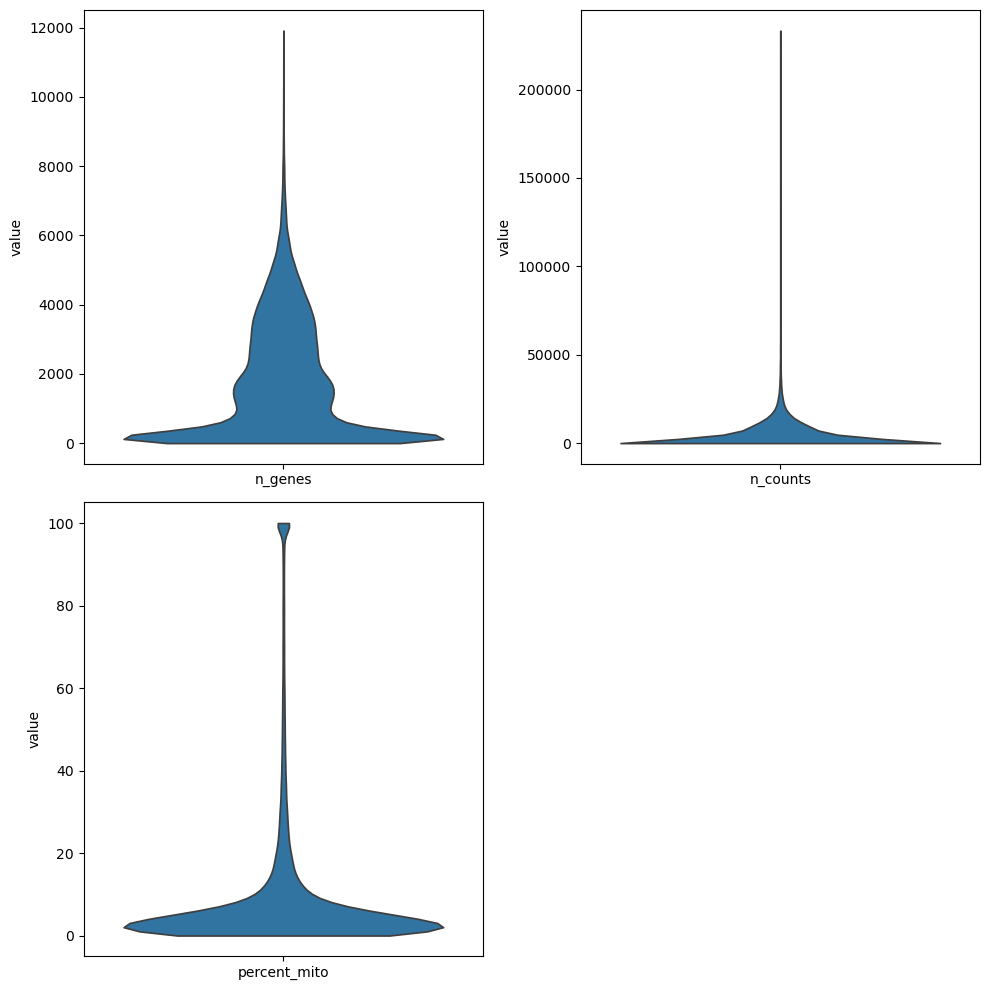

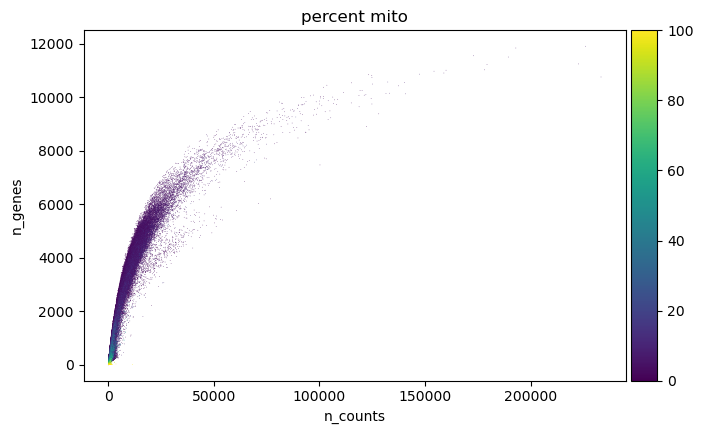

The 99th percentile all sample genes/cell is: 4990.0
The 99th percentile all sample total counts/cell is: 17839.0
The 99th percentile all sample mitochondrial % /cell is: 42.53079553413257


In [10]:
## Plot QC Metrics ##

# QC by counts #
# convert to pegasus unimodal object
rao_adata = UnimodalData(rao_adata)
pg.qc_metrics(rao_adata, mito_prefix='MT-')

# Create a figure with 3 subplots

# convert back for plotting to scanpy anndata
rao_adata = rao_adata.to_anndata()
fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes = axes.flatten()
sc.pl.violin(rao_adata, "n_genes", ax=axes[0], show=False, stripplot=False)
sc.pl.violin(rao_adata, "n_counts", ax=axes[1], show=False, stripplot=False)
sc.pl.violin(rao_adata, "percent_mito", ax=axes[2], show=False, stripplot=False)
fig.delaxes(axes[3])
plt.tight_layout()

sc.pl.scatter(rao_adata, "n_counts", "n_genes", color="percent_mito")

print('The 99th percentile all sample genes/cell is: {0}'.format(np.percentile(rao_adata.obs['n_genes'], 95)))

print('The 99th percentile all sample total counts/cell is: {0}'.format(np.percentile(rao_adata.obs['n_counts'], 95)))

print('The 99th percentile all sample mitochondrial % /cell is: {0}'.format(np.percentile(rao_adata.obs['percent_mito'], 95)))

n_UMIs lower: 88 upper: 83584
n_genes lower: 77 upper: 24694


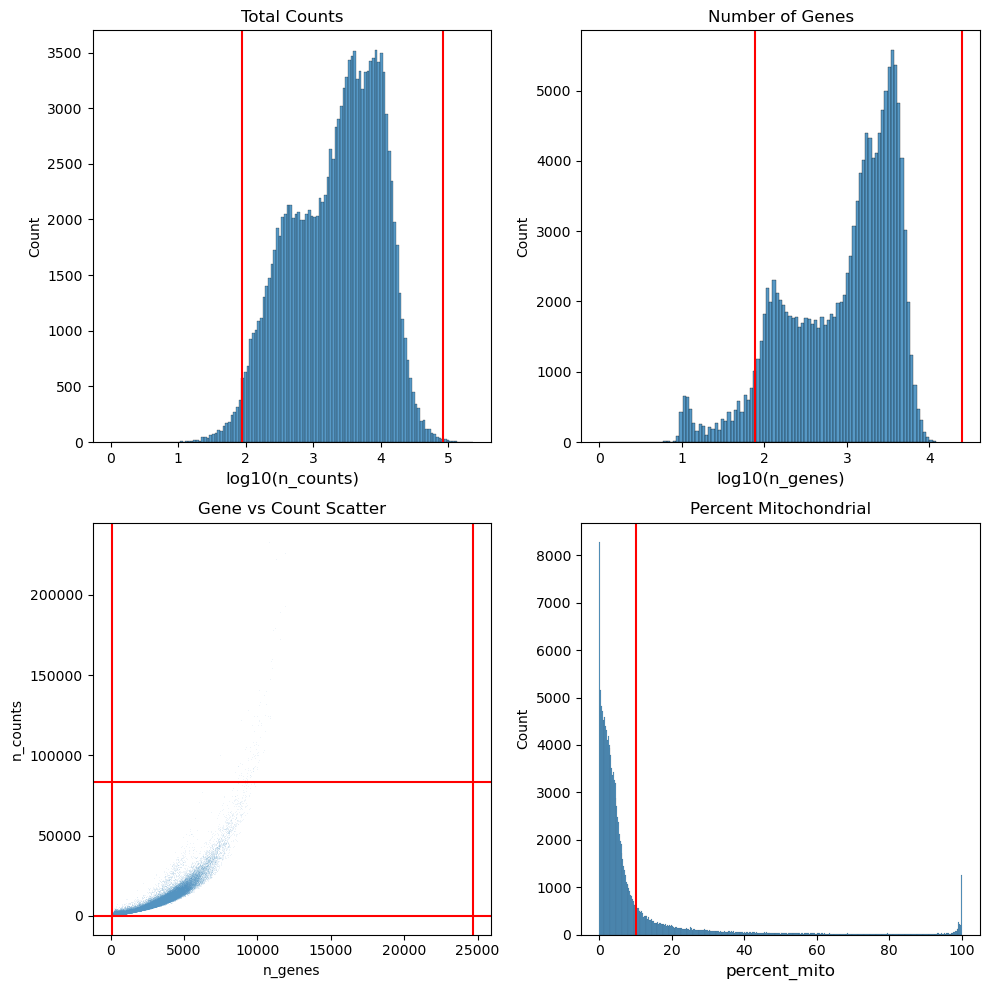

In [11]:
## Visualizating QC Cutoffs ##

MAD = 3

def qc_boundary(counts, k=MAD):
    x = np.log1p(counts)
    mad = median_abs_deviation(x)
    return np.exp(np.median(x) - k*mad), np.exp(np.median(x) + k*mad)

### nUMI and nGene QCs
n_counts_lower, n_counts_upper = qc_boundary(rao_adata.obs.n_counts, k=MAD)
print('n_UMIs lower: %d upper: %d' % (n_counts_lower, n_counts_upper))

n_genes_lower, n_genes_upper = qc_boundary(rao_adata.obs.n_genes, k=MAD)
print('n_genes lower: %d upper: %d' % (n_genes_lower, n_genes_upper))

## Plot Changes to Counts and Genes/Cell Distributions ##

fig, axs = plt.subplots(2, 2, figsize=(10, 10))  # 2x2 grid, adjust size as needed

# Plot 1: log10(n_counts)
sns.histplot(np.log10(rao_adata.obs.n_counts), ax=axs[0, 0])
axs[0, 0].axvline(np.log10(n_counts_lower), color='red')
axs[0, 0].axvline(np.log10(n_counts_upper), color='red')
axs[0, 0].set_xlabel('log10(n_counts)', fontsize=12)
axs[0, 0].set_title("Total Counts")

# Plot 2: log10(n_genes)
sns.histplot(np.log10(rao_adata.obs.n_genes), ax=axs[0, 1])
axs[0, 1].axvline(np.log10(n_genes_lower), color='red')
axs[0, 1].axvline(np.log10(n_genes_upper), color='red')
axs[0, 1].set_xlabel('log10(n_genes)', fontsize=12)
axs[0, 1].set_title("Number of Genes")

# Plot 3: scatter plot of n_genes vs n_counts
sns.scatterplot(x=rao_adata.obs.n_genes, y=rao_adata.obs.n_counts, alpha=0.5, s=0.1, ax=axs[1, 0])
axs[1, 0].axhline(n_counts_lower, color='red')
axs[1, 0].axhline(n_counts_upper, color='red')
axs[1, 0].axvline(n_genes_lower, color='red')
axs[1, 0].axvline(n_genes_upper, color='red')
axs[1, 0].set_xlabel('n_genes')
axs[1, 0].set_ylabel('n_counts')
axs[1, 0].set_title("Gene vs Count Scatter")

# Plot 4: percent_mito
sns.histplot(rao_adata.obs.percent_mito, ax=axs[1, 1])
axs[1, 1].axvline(10, color='red')
axs[1, 1].set_xlabel('percent_mito', fontsize=12)
axs[1, 1].set_title("Percent Mitochondrial")

plt.tight_layout()
plt.show()

n_cells before QC: 144551
n_cells after QC: 144551
mean n_cells before QC 8030.611111111111
mean n_cells after QC 8030.611111111111


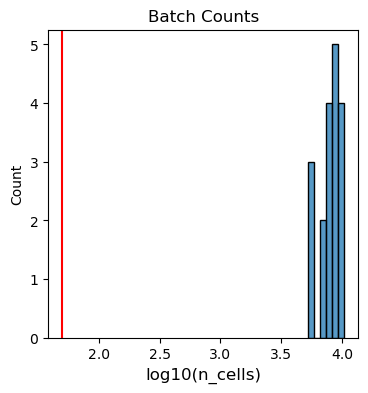

remove 0 batches that have cells less than 50


In [12]:
## Minimum Cell Cutoffs Based on Donor-Batches ##

args_min_n_cells = 50

n_cells_before_qc = rao_adata.obs.library.value_counts().rename_axis('library').reset_index(name='counts')
n_cells_after_qc = rao_adata.obs[rao_adata.obs.passed_qc].library.value_counts().rename_axis('library').reset_index(name='counts')

print('n_cells before QC:', np.sum(n_cells_before_qc[n_cells_before_qc.counts>0].counts))
print('n_cells after QC:', np.sum(n_cells_after_qc[n_cells_after_qc.counts>0].counts))

print('mean n_cells before QC', np.mean(n_cells_before_qc[n_cells_before_qc.counts>0].counts))
print('mean n_cells after QC', np.mean(n_cells_after_qc[n_cells_after_qc.counts>0].counts))

# Plot Distribution of Donor-Batches on Being Greater than Zero
plt.figure(figsize=(4, 4))
plt.title('Batch Counts')
sns.histplot(np.log10(n_cells_before_qc[n_cells_before_qc.counts>0].counts))
plt.axvline(np.log10(args_min_n_cells), color='red')
plt.xlabel('log10(n_cells)', fontsize=12)
plt.show()

### n_cells QC

#identify donor-batches with less than 50 cells of contribution
n_cells_outlier = list(n_cells_after_qc[n_cells_after_qc.counts<args_min_n_cells].library)
# set these to have failed QC as well
rao_adata.obs.loc[rao_adata.obs.library.isin(n_cells_outlier),'passed_qc'] = False
print('remove {0} batches that have cells less than {1}'.format(len(n_cells_outlier), args_min_n_cells))

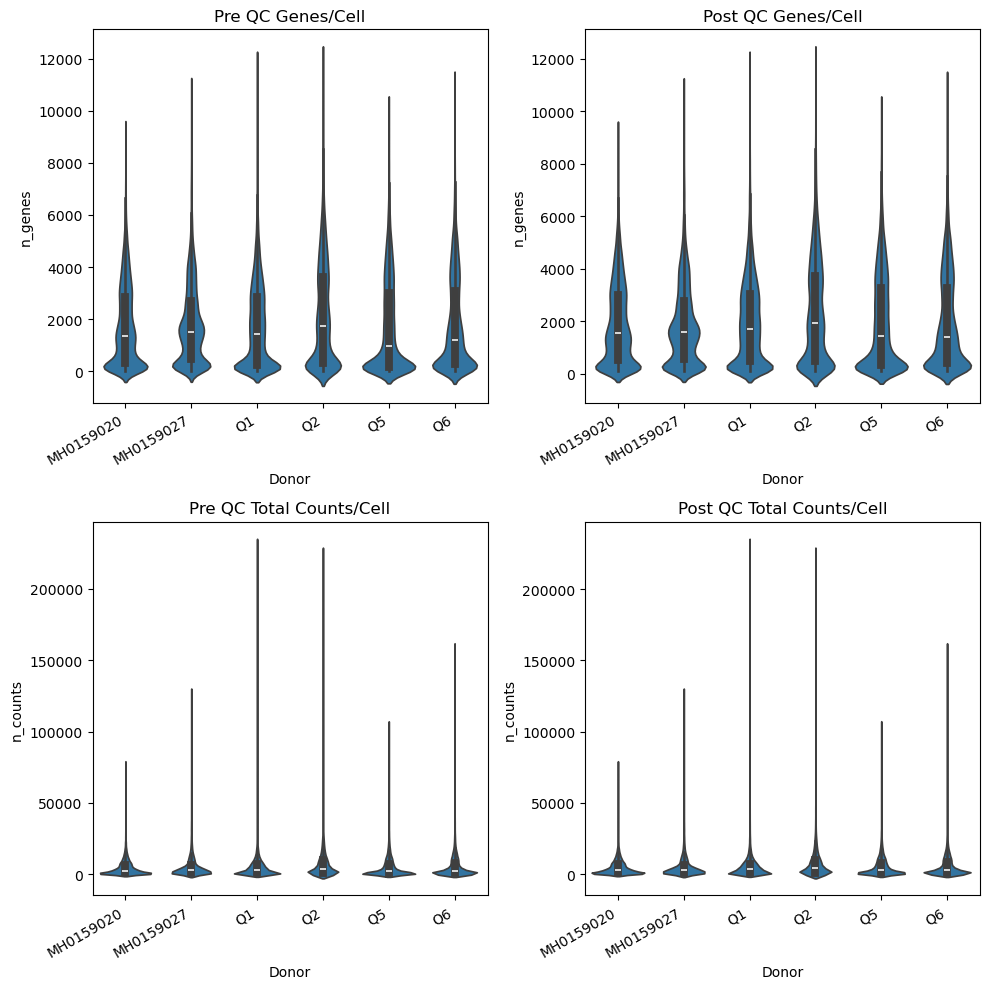

In [13]:
## Trialing QC Cutoffs Before and After ##

## Boolean Cutoffs for UMIs and Genes/Cell ##

counts_filter = (n_counts_lower < rao_adata.obs.n_genes) & (rao_adata.obs.n_genes < n_counts_upper)
genes_filter = (n_genes_lower < rao_adata.obs.n_genes) & (rao_adata.obs.n_genes < n_genes_upper)

# Plot Changes With Violins 

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
axes = axes.flatten()
sns.violinplot(data=rao_adata.obs, y='n_genes', x='Donor', ax=axes[0])
axes[0].set_title('Pre QC Genes/Cell')
plt.setp(axes[0].get_xticklabels(), rotation=30, ha='right')

sns.violinplot(data=rao_adata.obs[counts_filter & genes_filter], x='Donor', y='n_genes', ax=axes[1])
axes[1].set_title('Post QC Genes/Cell')
plt.setp(axes[1].get_xticklabels(), rotation=30, ha='right')

sns.violinplot(data=rao_adata.obs, y='n_counts', x='Donor', ax=axes[2])
axes[2].set_title('Pre QC Total Counts/Cell')
plt.setp(axes[2].get_xticklabels(), rotation=30, ha='right')

sns.violinplot(data=rao_adata.obs[rao_adata.obs.passed_qc & genes_filter], x='Donor', y='n_counts', ax=axes[3])
axes[3].set_title('Post QC Total Counts/Cell')
plt.setp(axes[3].get_xticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.show()

In [14]:
rao_adata.obs['Run'].value_counts().shape[0]

18

In [15]:
rao_adata.obs['Run'].value_counts().shape[0]/2

9.0

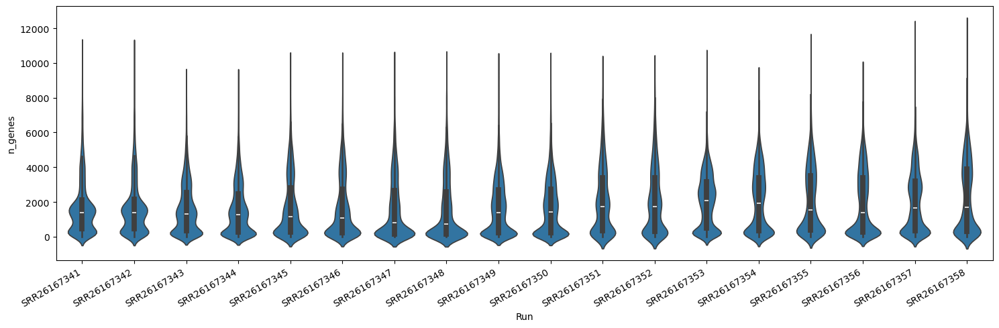

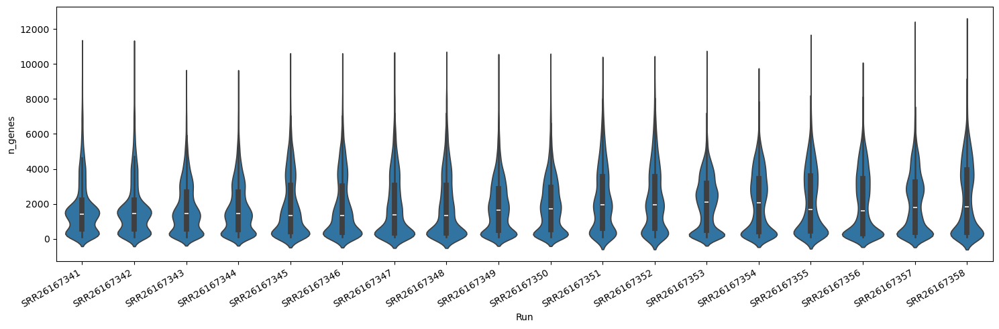

In [16]:
plt.figure(figsize=(15,5))
sns.violinplot(data=rao_adata.obs, x='Run', y='n_genes')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()

plt.figure(figsize=(15,5))
sns.violinplot(data=rao_adata.obs[counts_filter & genes_filter], x='Run', y='n_genes')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()

In [17]:
## Remove Cells That Don't Meet Total Counts/Cell and Genes/Cell Thresholds ##

rao_adata = MultimodalData(UnimodalData(rao_adata, modality="rna"))

pg.qc_metrics(rao_adata, 
              min_genes=n_genes_lower, max_genes=n_genes_upper,
              min_umis=n_counts_lower, max_umis=n_counts_upper,
              mito_prefix='MT-', percent_mito=10)

pg.filter_data(rao_adata)
gc.collect()
rao_adata = rao_adata.to_anndata()

2026-03-11 23:35:05,453 - pegasusio.qc_utils - INFO - After filtration, 113802 out of 144551 cell barcodes are kept in UnimodalData object unknown-rna.
2026-03-11 23:35:05,454 - pegasus.tools.preprocessing - INFO - Function 'filter_data' finished in 0.50s.


In [18]:
## Filter Cells and Genes With Raw Cutoffs #

# store raw counts in layer
rao_adata.layers["raw_counts"] = rao_adata.X

# Note: No cells fail this cutoff affter using MAD based filtration
print((rao_adata.obs.n_genes < 100).sum())
print((rao_adata.var.n_cells < 20).any())

# Doing This For Completeness
sc.pp.filter_cells(rao_adata, min_genes=100)
sc.pp.filter_genes(rao_adata, min_cells=20)

1491
False


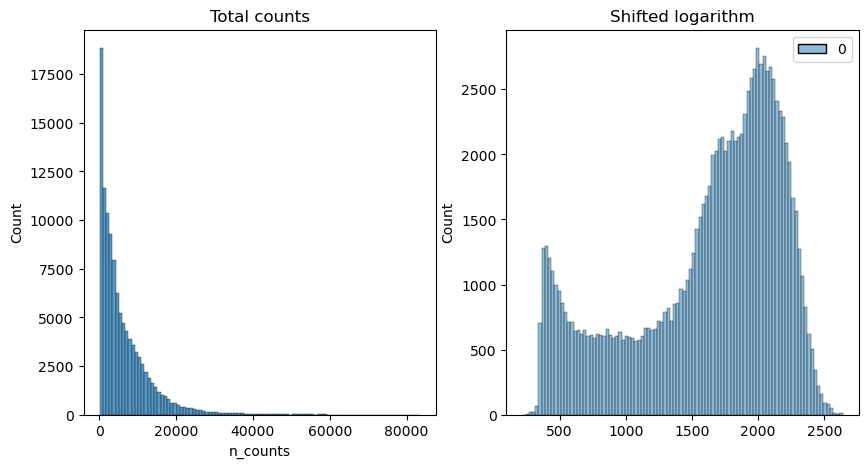

In [19]:
## Log Normalization ##

# normalize 
scales_counts = sc.pp.normalize_total(rao_adata, layer='raw_counts', target_sum=None, inplace=False)

# log1p transform
rao_adata.layers["log1p_norm"] = sc.pp.log1p(scales_counts["X"], copy=True)

# set X as log1p normed counts
rao_adata.X = rao_adata.layers["log1p_norm"]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
p1 = sns.histplot(rao_adata.obs["n_counts"], bins=100, kde=False, ax=axes[0])
axes[0].set_title("Total counts")
p2 = sns.histplot(rao_adata.layers["log1p_norm"].sum(1), bins=100, kde=False, ax=axes[1])
axes[1].set_title("Shifted logarithm")
plt.show()

2026-03-11 23:35:18,047 - pegasus.tools.utils - INFO - Loaded signatures from GMT file /home/deepak/pixi_envs/pegasus/.pixi/envs/default/lib/python3.10/site-packages/pegasus/data_files/cell_cycle_human.gmt.
2026-03-11 23:35:18,055 - pegasus.tools.signature_score - INFO - Signature G1/S: 43 out of 43 genes are used in signature score calculation.
2026-03-11 23:35:18,714 - pegasus.tools.signature_score - INFO - Signature G2/M: 54 out of 54 genes are used in signature score calculation.
2026-03-11 23:35:19,510 - pegasus.tools.signature_score - INFO - Function 'calc_signature_score' finished in 2.86s.
2026-03-11 23:35:31,235 - pegasus.tools.preprocessing - INFO - Function 'pca' finished in 5.28s.


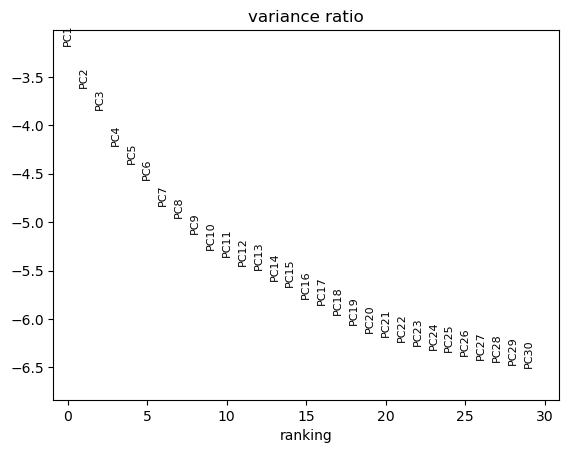

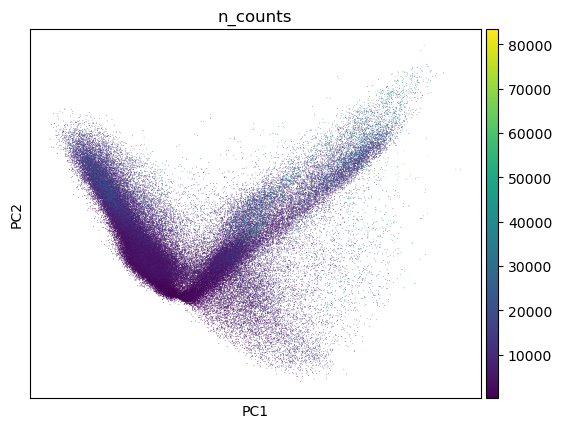

There is 20.461218695321268 variance explained by these components
2026-03-11 23:35:31,822 - pegasus.tools.preprocessing - INFO - Function 'regress_out' finished in 0.12s.
2026-03-11 23:35:31,824 - pegasus.tools.batch_correction - INFO - Start integration using Harmony.
	Initialization is completed.
	Completed 1 / 20 iteration(s).
	Completed 2 / 20 iteration(s).
	Completed 3 / 20 iteration(s).
	Completed 4 / 20 iteration(s).
	Completed 5 / 20 iteration(s).
	Completed 6 / 20 iteration(s).
Reach convergence after 6 iteration(s).
2026-03-11 23:35:54,675 - pegasus.tools.batch_correction - INFO - Function 'run_harmony' finished in 22.85s.
2026-03-11 23:36:06,598 - pegasus.tools.nearest_neighbors - INFO - Function 'get_neighbors' finished in 11.92s.
2026-03-11 23:36:08,766 - pegasus.tools.nearest_neighbors - INFO - Function 'calculate_affinity_matrix' finished in 2.17s.
2026-03-11 23:36:11,099 - pegasus.tools.graph_operations - INFO - Function 'construct_graph' finished in 2.33s.
2026-03-11 

/home/deepak/pixi_envs/pegasus/.pixi/envs/default/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Wed Mar 11 23:36:30 2026 Construct embedding


Epochs completed:   0%|            0/200 [00:00]

	completed  0  /  200 epochs
	completed  20  /  200 epochs
	completed  40  /  200 epochs
	completed  60  /  200 epochs
	completed  80  /  200 epochs
	completed  100  /  200 epochs
	completed  120  /  200 epochs
	completed  140  /  200 epochs
	completed  160  /  200 epochs
	completed  180  /  200 epochs
Wed Mar 11 23:37:13 2026 Finished embedding
2026-03-11 23:37:13,196 - pegasus.tools.visualization - INFO - Function 'umap' finished in 44.63s.


In [20]:
# Calculate Highly Variable Genes (not using deviance) ##

if not isinstance(rao_adata, UnimodalData):
    rao_adata = UnimodalData(rao_adata)

## ROUND 0 ##

# calc score requires a float downcast for some reason
rao_adata.X = rao_adata.X.astype('float32')
pg.calc_signature_score(rao_adata, 'cell_cycle_human')

# calculate HVGs on a protein_coding_autosomal only gene list
rao_hvg = rao_adata[:,rao_adata.var.robust_protein_coding_autosome].copy()
rao_hvg = rao_hvg.to_anndata()
hvg = sc.pp.highly_variable_genes(rao_hvg, layer='log1p_norm', n_top_genes=3000, inplace=False, subset=False)
hvg_list = rao_hvg.var.index[hvg.highly_variable].tolist()
del rao_hvg
gc.collect()

# apply that HVG list to your original anndata object
rao_adata.var['highly_variable_features'] = False
rao_adata.var['highly_variable_features'] = rao_adata.var.index.isin(hvg_list)

## Dimensionality Reduction ##

# PCA

if not isinstance(rao_adata, UnimodalData):
    rao_adata = UnimodalData(rao_adata)

pg.pca(rao_adata, n_components=30)
sc.pl.pca_variance_ratio(rao_adata, n_pcs=30, log=True)
sc.pl.pca_scatter(rao_adata.to_anndata(), color="n_counts")
plt.show()

print('There is {0} variance explained by these components'.format(rao_adata.uns['pca']['variance_ratio'].sum()*100))

# # Regress Out ##

pg.regress_out(rao_adata, ['n_counts', 'percent_mito'])

## Harmony  

pg.run_harmony(rao_adata, batch=['Donor'], rep='pca_regressed', max_iter_harmony=20, n_comps=30)

# # UMAP

pg.neighbors(rao_adata, rep='pca_regressed_harmony', use_cache=False, dist='l2', K=100, n_comps=30)
pg.leiden(rao_adata, rep='pca_regressed_harmony', resolution=0.1, class_label='class')
pg.umap(rao_adata, rep='pca_regressed_harmony', n_neighbors=15, rep_ncomps=30)
plt.show()

rao_adata = rao_adata.to_anndata()

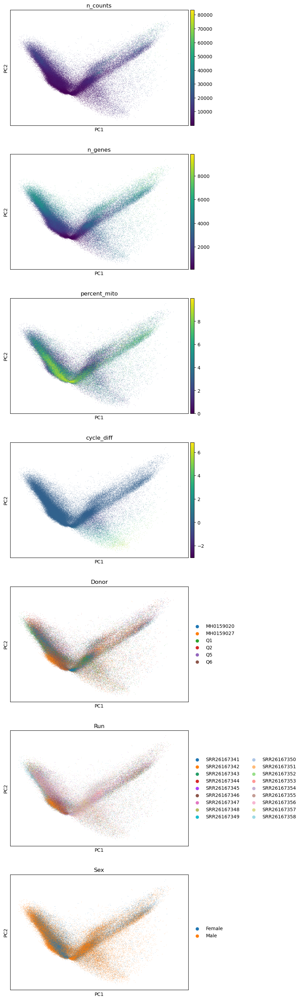

In [21]:
sc.pl.pca(rao_adata, color=["n_counts", "n_genes", "percent_mito", 'cycle_diff', 'Donor', 'Run', 'Sex'], ncols=1)

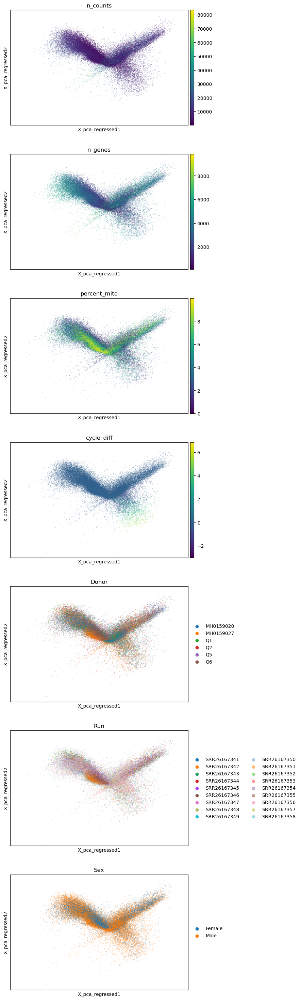

In [22]:
sc.pl.embedding(rao_adata, basis='X_pca_regressed', 
                color=["n_counts", "n_genes", "percent_mito", 'cycle_diff', 'Donor', 'Run', 'Sex'], ncols=1)

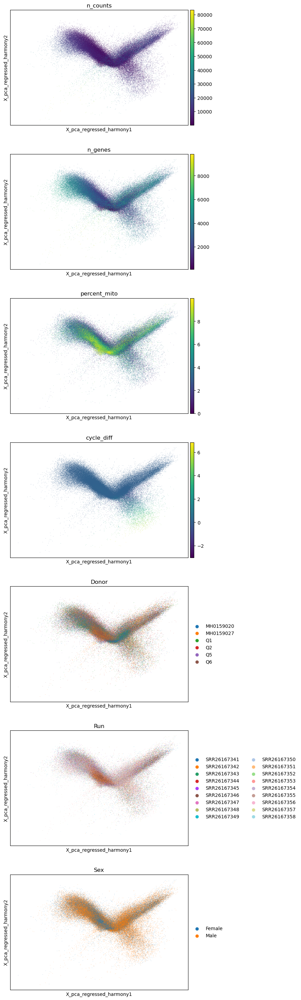

In [23]:
sc.pl.embedding(rao_adata, basis='X_pca_regressed_harmony', 
                color=["n_counts", "n_genes", "percent_mito", 'cycle_diff', 'Donor', 'Run', 'Sex'], ncols=1)

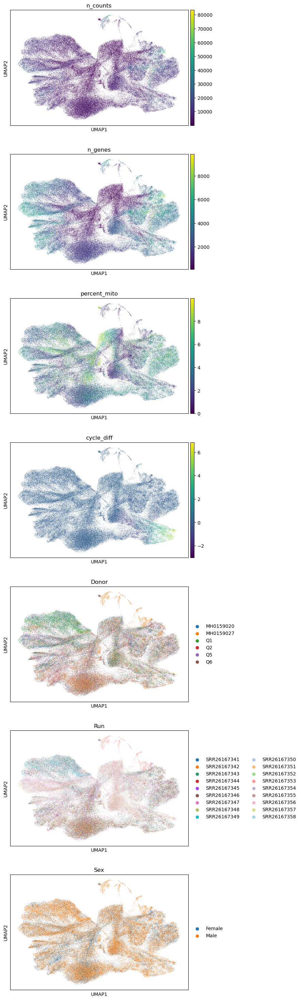

In [24]:
sc.pl.umap(rao_adata, color=["n_counts", "n_genes", "percent_mito", 'cycle_diff', 'Donor', 'Run', 'Sex'], ncols=1)

In [25]:
## Align Key Columns Across Datasets ##

rao_adata.obs['Day'] = rao_adata.obs['treatment'].str.split(' ').apply(lambda x: x[0]).str.strip('DIV').astype('int')
del rao_adata.obs['treatment'] # from Rao, integrated as Day
rao_adata.obs['Genotype'] = rao_adata.obs['genotype'].replace('Wild type', 'Control')
del rao_adata.obs['genotype']

rao_adata.obs['Manuscript'] = 'Rao'
rao_adata.obs['Protocol'] = 'Kadoshima'
rao_adata.obs['Whitelist'] = '3M-february-2018'
rao_adata.obs['Chemistry'] = '10xv3'

/tmp/ipykernel_3520910/752838863.py:5: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  rao_adata.obs['Genotype'] = rao_adata.obs['genotype'].replace('Wild type', 'Control')


In [26]:
## Cells After QC ##

rao_adata.X.shape[0]

112311

In [27]:
## Save Step ##

rao_adata.write_h5ad('/mnt/sdb/scz_meta_analysis_processed/studies/rao_gogos/anndata_objs/rao_qc.h5ad')

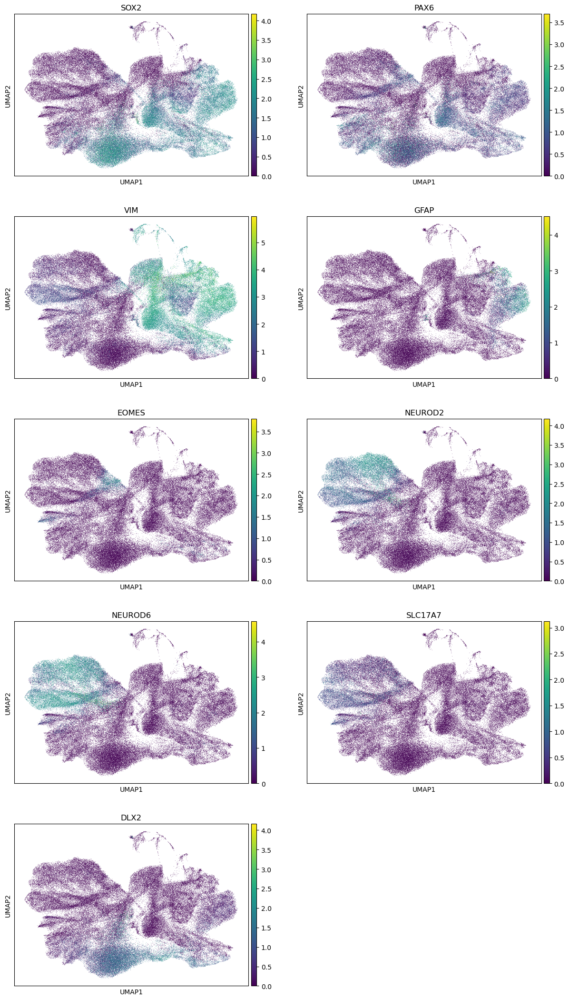

In [28]:
sc.pl.umap(rao_adata, color=['SOX2', 'PAX6', 'VIM', 'GFAP', 'EOMES', 'NEUROD2', 'NEUROD6', 'SLC17A7', 'DLX2'], ncols=2)